# 02 · The full workflow on a simulated price panel

This notebook runs the complete workflow on a **simulated** weekly price panel for 26 generic cities, named
City A to City Z and placed at random: an annual price cycle, Ramadan and Eid al-Fitr effects, and a synthetic
'hub' neighbourhood that has nothing to do with distance. No real price data are used.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('..'))   # or: pip install -e .  (from the repository root)
import numpy as np
import matplotlib.pyplot as plt
import gstarx_pw as g
from gstarx_pw.plotting import set_style, plot_links, plot_bootstrap, plot_heatmaps, OKABE_ITO as C
set_style()
import pandas as pd
from scipy.stats import chi2

(261, 26) weeks x cities;  design columns: ['intercept', 'sin1', 'cos1', 'sin2', 'cos2', 'ramadan', 'eid_week', 'post_eid']


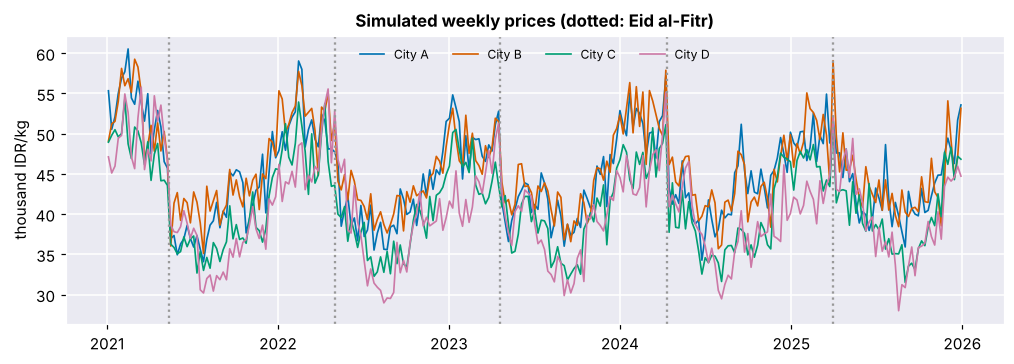

In [2]:
d = g.simulate_price_panel(seed=2026)
Y, X, names = d['y'], d['X'], d['names']
east, north = d['east_km'], d['north_km']
weeks = d['weeks'].astype('datetime64[D]')
print(Y.shape, 'weeks x cities;  design columns:', d['columns'])
fig, ax = plt.subplots(figsize=(11, 3.4))
for k in range(4):
    ax.plot(weeks, np.exp(Y[:, k]) / 1000, lw=1.1, label=names[k], color=C[k])
for e in g.EID_AL_FITR:
    ax.axvline(np.datetime64(e), color='#999999', ls=':')
ax.set_ylabel('thousand IDR/kg'); ax.set_title('Simulated weekly prices (dotted: Eid al-Fitr)'); ax.legend(ncol=4, fontsize=8); plt.show()

## 1. Exogenous stage: annual cycle and calendar variation

In [3]:
B, Zhat = g.exogenous_stage(Y, X)
M = g.annihilator(X)
est = pd.DataFrame({'estimated (mean)': B.mean(1), 'true (mean)': d['B_true'].mean(1)}, index=d['columns'])
est.iloc[1:].round(3)

,estimated (mean),true (mean)
sin1,0.135,0.119
cos1,0.077,0.098
sin2,-0.000,0.003
cos2,-0.002,0.002
ramadan,0.006,0.049
eid_week,0.077,0.097
post_eid,-0.087,-0.039


With only five Eid al-Fitr events in five years and strongly co-moving deviations across locations, the calendar coefficients carry noticeable estimation error; the annual cycle is estimated precisely. This uncertainty is exactly what the two-stage bootstrap of the Wald test takes into account.

## 2. Is a first-order space–time stage adequate? Residual diagnostics

In [4]:
p0, p1, _ = g.fixed_fit(Zhat, d['W0'])
A_fix = np.diag(p0) + p1[:, None] * d['W0']
kappa, fit = g.select_kappa(Zhat, d['W0'])
res = {'exogenous stage only': Zhat[1:], 'GSTARX, inverse distance': Zhat[1:] - Zhat[:-1] @ A_fix.T,
       'GSTARX-PW': Zhat[1:] - Zhat[:-1] @ fit['A'].T}
pd.DataFrame({k: {'locations rejecting white noise (Ljung-Box, 12 lags)': int((g.ljung_box(r)[1] < 0.05).sum()),
                  'residual s.d.': r.std()} for k, r in res.items()}).T.round(4)

,"locations rejecting white noise (Ljung-Box, 12 lags)",residual s.d.
exogenous stage only,26.0,0.0613
"GSTARX, inverse distance",2.0,0.0542
GSTARX-PW,3.0,0.0506


## 3. Test the four standard weight matrices (and the truth as a control)

In [5]:
rng = np.random.default_rng(11)
crit = chi2.ppf(0.95, len(names) - 2)
cands = {'uniform': g.uniform_matrix(len(names)), 'inverse distance': d['W0'],
         '4-nearest neighbours': g.knn_matrix(north, east, 4, kind='euclidean'), 'cross-correlation': g.cross_correlation_matrix(Zhat),
         'true W (control)': d['W_true']}
rows = {}
for k, W in cands.items():
    p, Wi = g.bootstrap_test(Zhat, W, M, rng, B=199)
    rows[k] = {'W_tot': Wi.sum(), 'bootstrap p': p, 'equations rejected (chi2, 5%)': int((Wi > crit).sum())}
pd.DataFrame(rows).T.round(3)

,W_tot,bootstrap p,"equations rejected (chi2, 5%)"
uniform,1413.490,0.005,26.0
inverse distance,1450.023,0.005,26.0
4-nearest neighbours,1542.232,0.005,26.0
cross-correlation,1311.010,0.005,26.0
true W (control),624.551,0.615,1.0


## 4. The estimated neighbourhood
Circles mark the four synthetic hubs.

selected kappa: 0.0 | MAE prior 0.0733 -> GSTARX-PW 0.0223


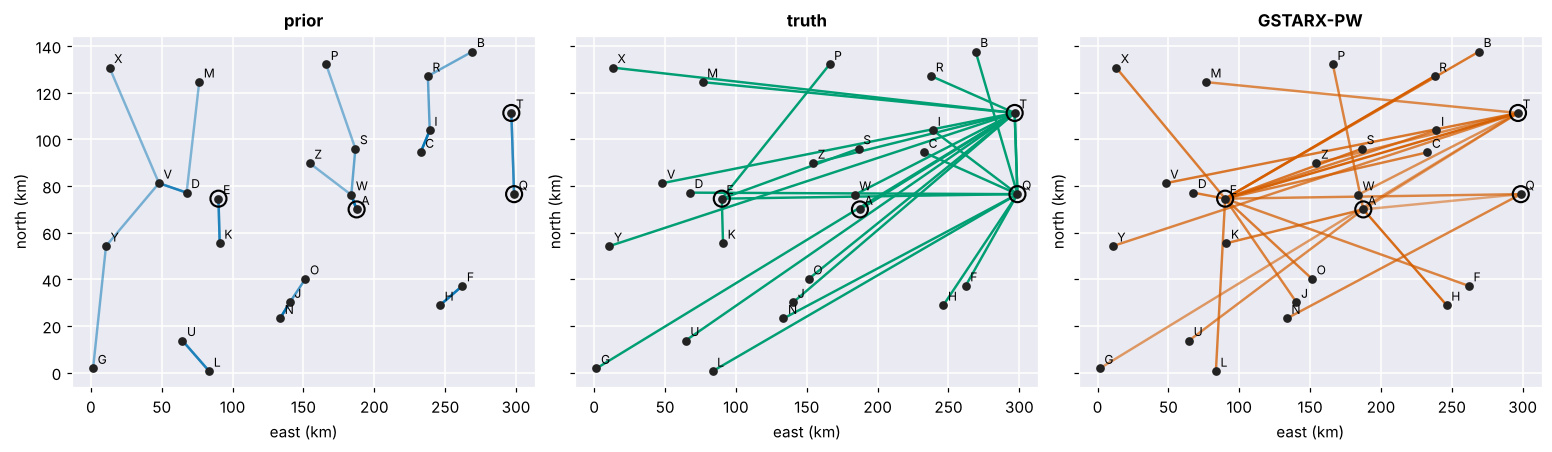

synthetic hubs: ['City A', 'City T', 'City Q', 'City E']


In [6]:
print('selected kappa:', kappa, '| MAE prior %.4f -> GSTARX-PW %.4f' % (g.mae_offdiag(d['W0'], d['W_true']), g.mae_offdiag(fit['W'], d['W_true'])))
fig, ax = plt.subplots(1, 3, figsize=(14, 4), sharey=True, constrained_layout=True)
for a, (W, t, c) in zip(ax, [(d['W0'], 'prior', C[0]), (d['W_true'], 'truth', C[2]), (fit['W'], 'GSTARX-PW', C[1])]):
    plot_links(a, north, east, W, k=1, color=c, labels=[n.split()[1] for n in names], xlabel='east (km)', ylabel='north (km)'); a.set_title(t)
    a.scatter(east[d['hubs']], north[d['hubs']], s=110, facecolors='none', edgecolors='black', lw=1.4, zorder=4)
plt.show()
print('synthetic hubs:', [names[h] for h in d['hubs']])

## 5. Rolling-origin forecasts
The exogenous stage and all models are re-estimated at every origin (here every fourth week, with $\kappa$ fixed at the value selected on the first window to keep the notebook fast).

In [7]:
k1, _ = g.select_kappa(g.exogenous_stage(Y[:156], X[:156])[1], d['W0'])
errs, _ = g.rolling_origin(Y, X, d['W0'], window=156, H=4, step=4, kappa=k1)
rmse = pd.DataFrame({m: np.sqrt((e ** 2).mean(axis=(0, 2))) for m, e in errs.items()}, index=[f'h={h}' for h in range(1, 5)])
print((rmse.div(rmse['exog'], axis=0)).round(3).to_string())
for other in ['fixed', 'var', 'exog']:
    s, pv = g.dm_test(np.sqrt((errs['pw'][:, 0] ** 2).mean(1)), np.sqrt((errs[other][:, 0] ** 2).mean(1)))
    print(f'DM test, GSTARX-PW vs {other:5s}: statistic {s:6.2f}, p = {pv:.3f}')

     exog    var  fixed     pw
h=1   1.0  0.915  0.917  0.850
h=2   1.0  0.993  0.936  0.913
h=3   1.0  1.034  0.986  0.986
h=4   1.0  0.994  0.995  0.983
DM test, GSTARX-PW vs fixed: statistic  -2.49, p = 0.020
DM test, GSTARX-PW vs var  : statistic  -2.58, p = 0.016
DM test, GSTARX-PW vs exog : statistic  -1.78, p = 0.087


The choice of weight matrix matters little for point forecasts; it matters for **inference and interpretation** — which matrix is adequate, and which locations drive which.